In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
sns.set_theme(style="whitegrid")

CORE = ["tensile_strength_MPa", "yield_strength_MPa", "elongation_pct",
        "youngs_modulus_GPa", "density_g_cm3"]
X = pd.read_csv("../data/processed/materials_scaled.csv", index_col=0)
meta = pd.read_csv("../data/processed/materials_clustered.csv", index_col=0).loc[X.index]
print(X.shape, meta.shape)

(1235, 5) (1235, 27)


Variance explained: [0.607 0.28  0.073 0.032 0.008]
Cumulative:         [0.607 0.887 0.96  0.992 1.   ]


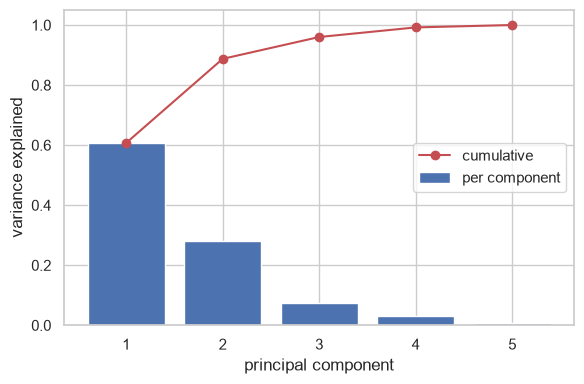

,PC1,PC2,PC3,PC4,PC5
tensile_strength_MPa,0.53,-0.19,0.39,-0.19,0.70
yield_strength_MPa,0.49,-0.39,0.37,-0.03,-0.69
elongation_pct,0.02,0.79,0.60,0.10,-0.11
youngs_modulus_GPa,0.52,0.17,-0.36,0.75,0.05
density_g_cm3,0.45,0.41,-0.47,-0.62,-0.14


In [8]:
pca = PCA(n_components=5, random_state=42).fit(X)
evr = pca.explained_variance_ratio_
print("Variance explained:", evr.round(3))
print("Cumulative:        ", np.cumsum(evr).round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(range(1, 6), evr, label="per component")
ax.plot(range(1, 6), np.cumsum(evr), "ro-", label="cumulative")
ax.set_xlabel("principal component"); ax.set_ylabel("variance explained"); ax.legend()
plt.tight_layout(); plt.savefig("../figures/06_scree.png", dpi=150); plt.show()

loadings = pd.DataFrame(pca.components_.T, index=CORE, columns=[f"PC{i+1}" for i in range(5)])
display(loadings.round(2))

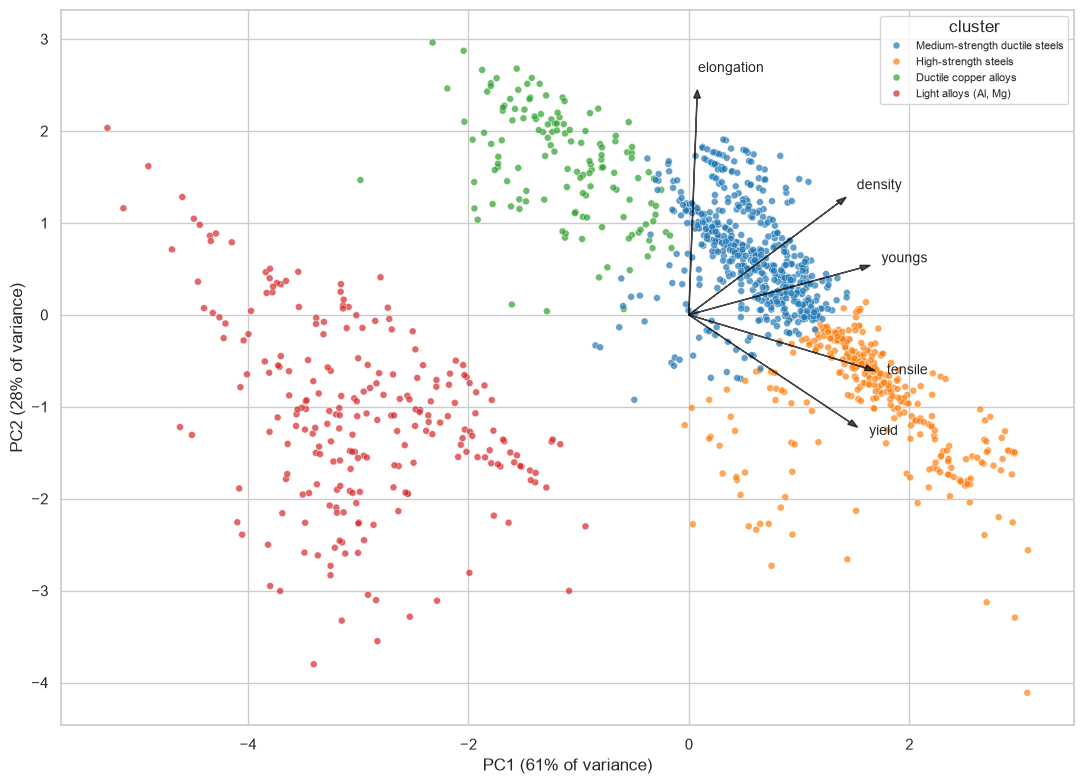

In [9]:
P = pca.transform(X)
fig, ax = plt.subplots(figsize=(11, 8))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=meta["cluster_name"].values,
                palette="tab10", s=25, alpha=0.7, ax=ax)

scale = 3.0   # arrow length, cosmetic only
for i, f in enumerate(CORE):
    ax.arrow(0, 0, pca.components_[0, i] * scale, pca.components_[1, i] * scale,
             color="black", alpha=0.7, head_width=0.06)
    ax.text(pca.components_[0, i] * scale * 1.12, pca.components_[1, i] * scale * 1.12,
            f.split("_")[0], fontsize=10)

ax.set_xlabel(f"PC1 ({evr[0]*100:.0f}% of variance)")
ax.set_ylabel(f"PC2 ({evr[1]*100:.0f}% of variance)")
ax.legend(title="cluster", loc="best", fontsize=8)
plt.tight_layout(); plt.savefig("../figures/06_pca_clusters.png", dpi=150); plt.show()

# ## PCA findings
# - The first two principal components capture 88.7% of the variance (PC1 60.7%, PC2 28.0%), so the 2D projection is a faithful view of the 5-feature data.
# - PC1 loads almost equally on tensile strength, yield strength, modulus and density (0.45-0.53) and not on elongation: it is an overall "heft" axis separating light alloys (left) from dense, stiff, strong steels (right).
# - PC2 is dominated by elongation (0.79) against yield strength (-0.39): it is the ductility-versus-strength axis, separating ductile copper alloys (top) from high-strength steels (bottom).
# - The four K-Means clusters occupy distinct regions. The medium- and high-strength steel clusters meet along a continuous band with no gap, consistent with the lack of a natural boundary within steel and with the K-Means/Ward disagreement.

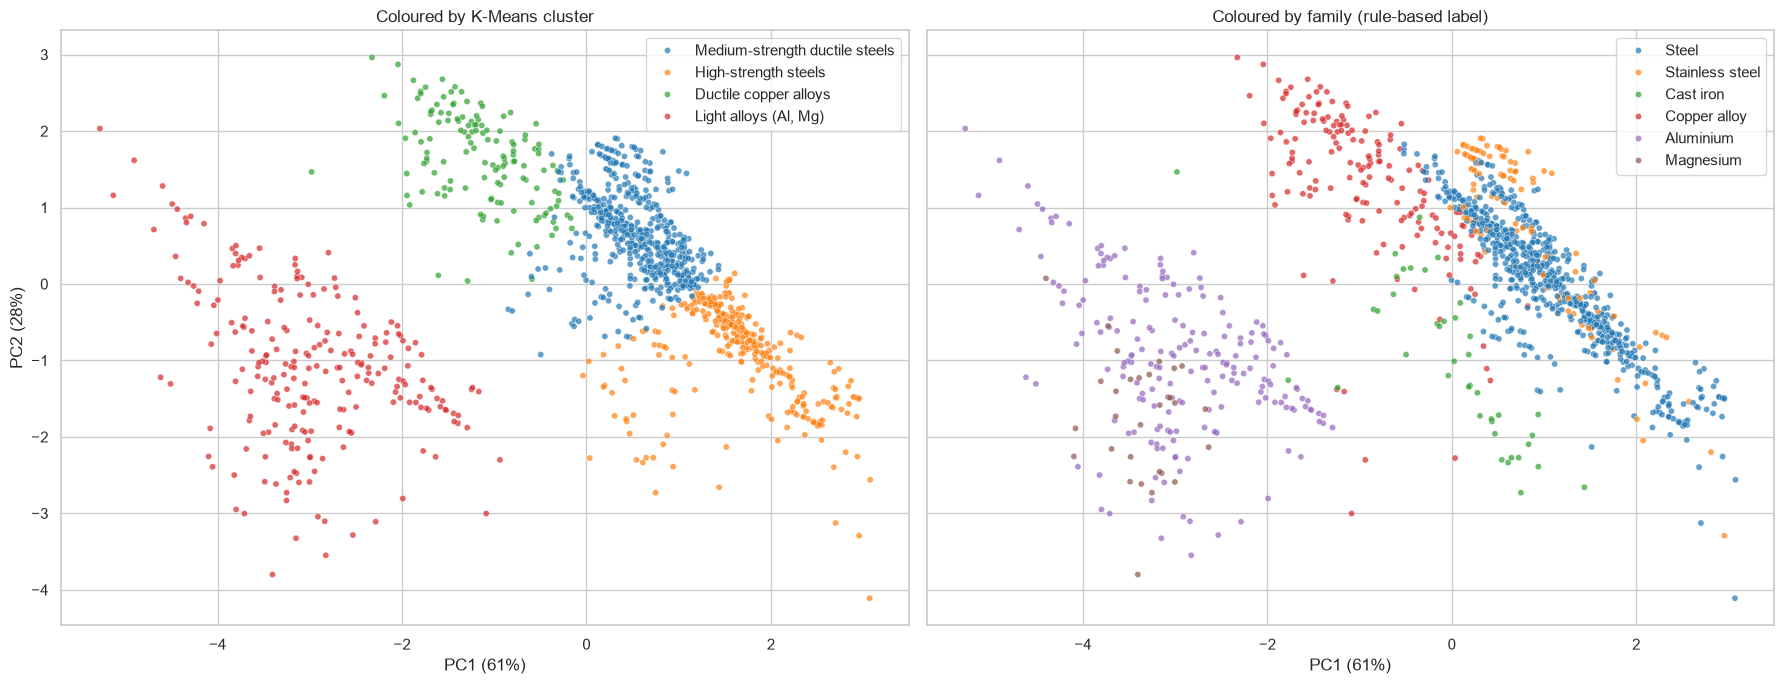

In [10]:
P = pca.transform(X)
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=True, sharey=True)
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=meta["cluster_name"].values,
                palette="tab10", s=20, alpha=0.7, ax=axes[0])
axes[0].set_title("Coloured by K-Means cluster")
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=meta["family"].values,
                palette="tab10", s=20, alpha=0.7, ax=axes[1])
axes[1].set_title("Coloured by family (rule-based label)")
for ax in axes:
    ax.set_xlabel(f"PC1 ({evr[0]*100:.0f}%)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.0f}%)")
plt.tight_layout(); plt.savefig("../figures/06_pca_clusters_vs_family.png", dpi=150); plt.show()

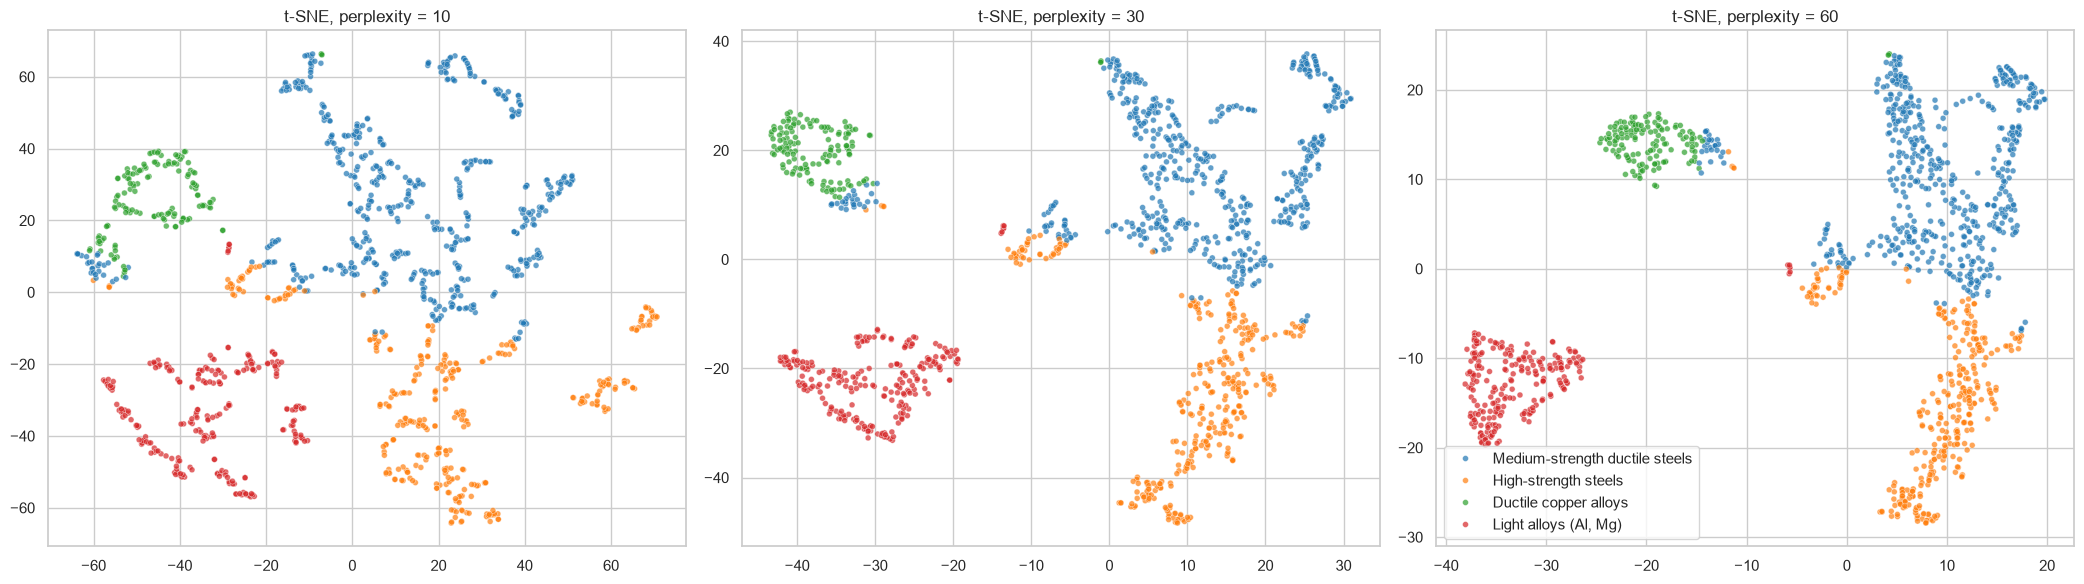

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
tsne_results = {}
for ax, perp in zip(axes, [10, 30, 60]):
    T = TSNE(n_components=2, perplexity=perp, init="pca",
             learning_rate="auto", random_state=42).fit_transform(X)
    tsne_results[perp] = T
    sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=meta["cluster_name"].values,
                    palette="tab10", s=18, alpha=0.7, ax=ax, legend=(perp == 60))
    ax.set_title(f"t-SNE, perplexity = {perp}")
plt.tight_layout(); plt.savefig("../figures/06_tsne.png", dpi=150); plt.show()

In [12]:
print("PCA 2D trustworthiness:", round(trustworthiness(X, P[:, :2], n_neighbors=10), 3))
for perp, T in tsne_results.items():
    print(f"t-SNE (perplexity={perp}) trustworthiness:", round(trustworthiness(X, T, n_neighbors=10), 3))

PCA 2D trustworthiness: 0.982
t-SNE (perplexity=10) trustworthiness: 0.997
t-SNE (perplexity=30) trustworthiness: 0.998
t-SNE (perplexity=60) trustworthiness: 0.997


# ## Clusters, families and t-SNE
# - Aluminium and magnesium alloys occupy one region (the light-alloy cluster), and copper alloys another. Steel and stainless steel overlap in a single band, so the five mechanical properties do not separate them.
# - Cast irons lie below the main steel band (lower ductility for their strength) and partly fall into the high-strength cluster.
# - t-SNE at perplexities 10, 30 and 60 keeps the same four groups together, with the two steel clusters touching. Low perplexity fragments the data into strings, so those fine structures are not interpreted. Distances between t-SNE islands are not meaningful.
# - Trustworthiness (10 neighbours): PCA 0.982; t-SNE 0.997-0.998. Both projections preserve local neighbourhoods well; PCA is used for global geometry and interpretable axes.